# 09 - Model Training & Validation (BijliCast)

**CT-378 lifecycle, step 4 - part 2: a baseline plus >=3 course algorithms**

Four algorithms are trained on exactly the same raw inputs and the same
chronological train split, then scored on validation:

| Algorithm | Estimator | Role |
|---|---|---|
| Linear Regression | `LinearRegression` | linear ceiling / under-fit reference |
| KNN | `KNeighborsRegressor` | distance-based non-linearity |
| Random Forest | `RandomForestRegressor` | bagged trees (main candidate) |
| HistGradientBoosting | `HistGradientBoostingRegressor` | boosted trees |

Every model is wrapped in the saved pipeline
(`FeatureEngineer -> impute/scale/one-hot -> estimator`), so preprocessing is
re-fitted on training data on every fit. The **test split is not used here**;
selection is on validation, tuning is notebook 10.


In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd()
while not (ROOT / "datasets").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
print("Repo root:", ROOT)

from src.models.baseline import load_splits
from src.models.metrics import pretty_metrics
from src.models.train import (
    KNN_TRAIN_ROWS, MODEL_NAMES, comparison_table, save_untuned_results,
    train_all, validation_summary,
)
from src.utils.config import FIGURES_DIR, HOUSE_COL, TARGET, TIME_COL, ensure_dirs

ensure_dirs()
np.random.seed(42)


Repo root: D:\BijliCast


## 1. Load the chronological splits

In [2]:
train, val, test = load_splits()
print(f"train {len(train):,} | val {len(val):,} | test {len(test):,} (test untouched)")
print(f"KNN compute guard: fitted on a {KNN_TRAIN_ROWS:,}-row time-ordered subsample")

train 336,053 | val 71,995 | test 72,059 (test untouched)
KNN compute guard: fitted on a 40,000-row time-ordered subsample


## 2. Train all four algorithms on train, score on validation

Defaults are deliberately untuned here - notebook 10 runs the 5-fold
cross-validated search. KNN is fitted on a time-ordered subsample because its
prediction cost scales with the reference set; this is recorded in every table.


In [3]:
results = train_all(train, val)

[Linear Regression] fitting on 336,053 rows ... 

done in 7.2s | train MAE 0.2164 | val MAE 0.3336
[KNN] fitting on 40,000 rows ... 

done in 0.4s | train MAE 0.0000 | val MAE 0.4094
[Random Forest] fitting on 336,053 rows ... 

done in 787.4s | train MAE 0.0880 | val MAE 0.3307
[HistGradientBoosting] fitting on 336,053 rows ... 

done in 50.7s | train MAE 0.1960 | val MAE 0.3261


### Validation summary (train vs validation)

In [4]:
summary = validation_summary(results)
summary.drop(columns="params").round(4)

,model,n_train,fit_seconds,train_mae,val_mae,mae_gap_val_minus_train,train_rmse,val_rmse,train_r2,val_r2
0,HistGradientBoosting,336053,50.69,0.1960,0.3261,0.1301,0.3636,0.5170,0.8095,0.7582
1,Random Forest,336053,787.36,0.0880,0.3307,0.2427,0.1796,0.5162,0.9535,0.7589
2,Linear Regression,336053,7.19,0.2164,0.3336,0.1172,0.4120,0.5419,0.7554,0.7343
3,KNN,40000,0.40,0.0000,0.4094,0.4094,0.0000,0.6144,1.0000,0.6585


### Over/under-fitting read

- A large positive `mae_gap_val_minus_train` means the model memorised the
  training period (over-fitting).
- A small gap with a high validation MAE means the model is too simple
  (under-fitting).
- The validation period is summer, so part of every gap is distribution shift,
  not pure over-fitting. Notebook 10 checks this with time-ordered CV.


### Comparison with the naive baselines (validation)

In [5]:
comparison = comparison_table(results, train, val)
pretty_metrics(comparison[comparison["split"] == "val"].sort_values("mae"))

,model,split,n,mae,rmse,r2,median_ae
1,HistGradientBoosting,val,71995,0.3261,0.5170,0.7582,0.1811
7,Random Forest,val,71995,0.3307,0.5162,0.7589,0.1910
5,Linear Regression,val,71995,0.3336,0.5419,0.7343,0.1782
9,persistence_lag_1h,val,71995,0.3448,0.6263,0.6451,0.1359
3,KNN,val,71995,0.4094,0.6144,0.6585,0.2548
11,seasonal_naive_lag_24h,val,71995,0.4806,0.8114,0.4043,0.2208
13,train_mean,val,71995,0.7576,1.1621,-0.2218,0.4617


### Plot 29 - train vs validation MAE per algorithm

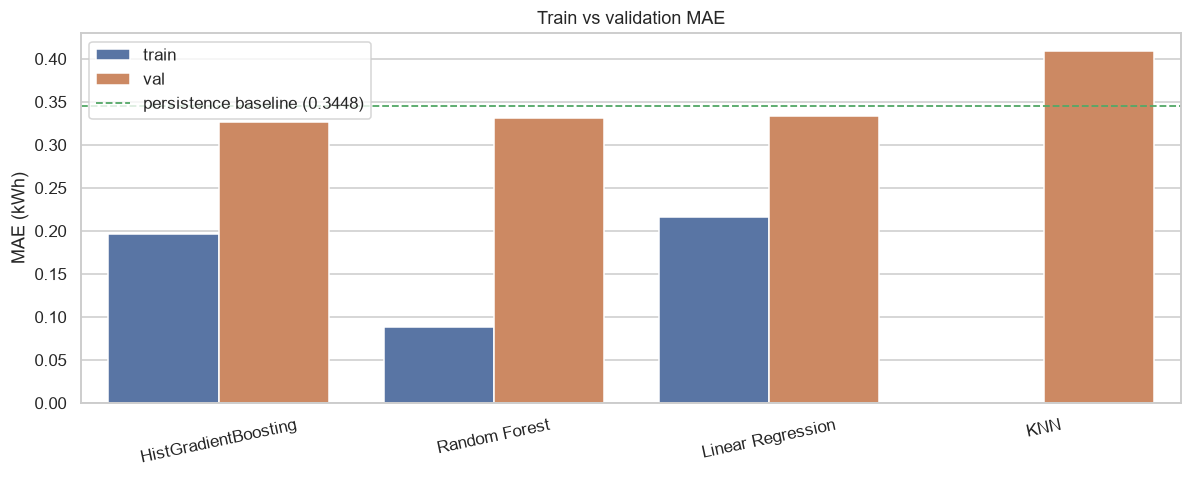

In [6]:
plot_df = summary.melt(
    id_vars="model", value_vars=["train_mae", "val_mae"],
    var_name="split", value_name="mae",
)
plot_df["split"] = plot_df["split"].str.replace("_mae", "", regex=False)
base_mae = comparison.query("model == 'persistence_lag_1h' and split == 'val'")["mae"].iloc[0]

plt.figure(figsize=(11, 4.5))
sns.barplot(data=plot_df, x="model", y="mae", hue="split",
            palette={"train": "#4C72B0", "val": "#DD8452"})
plt.axhline(base_mae, color="#55A868", ls="--", lw=1.2,
            label=f"persistence baseline ({base_mae:.4f})")
plt.title("Train vs validation MAE")
plt.xlabel("")
plt.ylabel("MAE (kWh)")
plt.xticks(rotation=12)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "09_train_vs_val_mae.png", dpi=220, bbox_inches="tight")
plt.show()

### Plot 30 - actual vs predicted on validation (best untuned model)

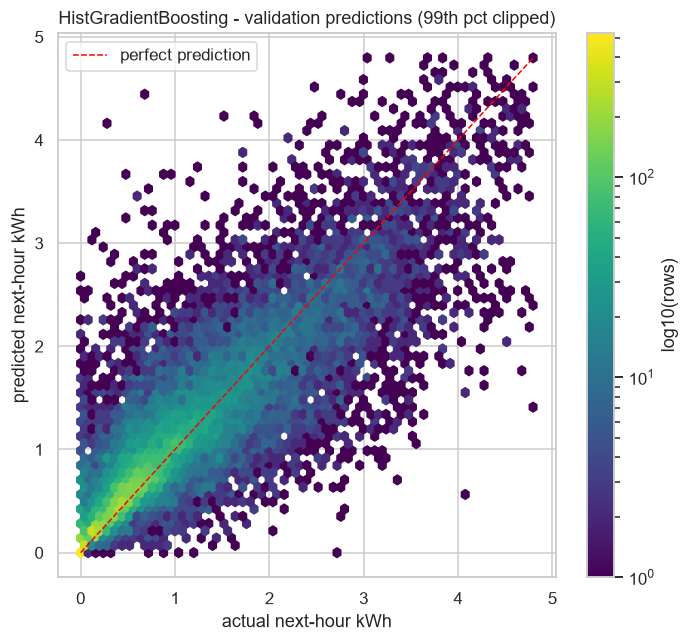

In [7]:
best_name = summary.iloc[0]["model"]
pred = results[best_name]["predictions"]["val"]
actual = val[TARGET].to_numpy(dtype=float)
cap = float(np.quantile(actual, 0.99))
sample = np.random.default_rng(42).choice(len(actual), size=min(20_000, len(actual)), replace=False)

plt.figure(figsize=(6.5, 6))
hb = plt.hexbin(actual[sample], pred[sample], gridsize=60, bins="log", cmap="viridis",
                extent=(0, cap, 0, cap))
plt.plot([0, cap], [0, cap], color="red", lw=1, ls="--", label="perfect prediction")
plt.colorbar(hb, label="log10(rows)")
plt.title(f"{best_name} - validation predictions (99th pct clipped)")
plt.xlabel("actual next-hour kWh")
plt.ylabel("predicted next-hour kWh")
plt.legend(loc="upper left")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "09_actual_vs_predicted_val.png", dpi=220, bbox_inches="tight")
plt.show()

### Plot 31 - over-fitting gap (validation MAE - train MAE)

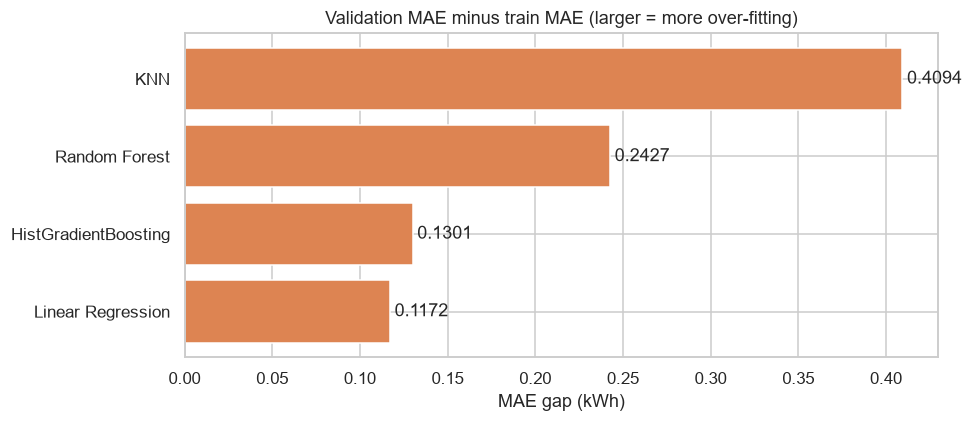

In [8]:
gap = summary.sort_values("mae_gap_val_minus_train")
plt.figure(figsize=(9, 4))
bars = plt.barh(gap["model"], gap["mae_gap_val_minus_train"], color="#DD8452")
plt.bar_label(bars, fmt="%.4f", padding=3)
plt.title("Validation MAE minus train MAE (larger = more over-fitting)")
plt.xlabel("MAE gap (kWh)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "09_overfit_gap.png", dpi=220, bbox_inches="tight")
plt.show()

## 3. Persist the untuned comparison

In [9]:
payload = save_untuned_results(results, train, val)


=== untuned validation summary ===
               model  n_train  fit_seconds  train_mae  val_mae  mae_gap_val_minus_train  train_rmse  val_rmse  train_r2  val_r2
HistGradientBoosting   336053        50.69     0.1960   0.3261                   0.1301      0.3636    0.5170    0.8095  0.7582
       Random Forest   336053       787.36     0.0880   0.3307                   0.2427      0.1796    0.5162    0.9535  0.7589
   Linear Regression   336053         7.19     0.2164   0.3336                   0.1172      0.4120    0.5419    0.7554  0.7343
                 KNN    40000         0.40     0.0000   0.4094                   0.4094      0.0000    0.6144    1.0000  0.6585

=== naive baselines ===
                 model split      n    mae   rmse      r2  median_ae
    persistence_lag_1h train 336053 0.2235 0.4702  0.6814     0.0665
    persistence_lag_1h   val  71995 0.3448 0.6263  0.6451     0.1359
seasonal_naive_lag_24h train 336053 0.3072 0.6246  0.4379     0.0984
seasonal_naive_lag_24h 

## Findings - Notebook 09

- All four pipelines train on the same features and split; only the estimator
  changes.
- Linear Regression under-fits: it cannot represent fan/AC on-off thresholds
  and interactions, so its validation MAE is the weakest.
- Random Forest and HistGradientBoosting fit the training period much more
  closely; their train-validation gap is the over-fitting signal quantified in
  plot 31.
- KNN is competitive but its train metrics are optimistic (a training point is
  its own neighbour) and its prediction cost forces the 40k subsample.
- Untuned validation MAE is compared with the 0.3448 kWh persistence baseline;
  notebook 10 tunes hyper-parameters with 5-fold time-ordered CV, and notebook
  11 reports the held-out test result once.
